# Exemplo apartado — Leitores PySDDP → PL Único

- Lê o cadastro de Batalha e Serra do Facão com `Hidr` e as vazões com `Vazoes`.
- Alimenta a mesma formulação PL Único do notebook principal e resolve com PySCIPOpt/SCIP.
- Usa arquivos públicos de exemplo do PySDDP com commit e hashes fixos; não é uma exportação do caso 103.

## 1. Bibliotecas

In [1]:
%pip -q install pysddp==0.0.90 pyscipopt numpy pandas matplotlib

"""PL Único determinístico: mesma formulação e funções do notebook da disciplina."""
from copy import deepcopy
from time import perf_counter

import numpy as np
import pandas as pd
from pyscipopt import Model, quicksum, SCIP_PARAMSETTING

escala_det = 1_000_000.0


def validar_sistema_det(sistema, cenario):
    geral, uhes, utes = sistema['DGer'], sistema['UHE'], sistema['UTE']
    n = len(geral['Meses'])
    carga = np.asarray(geral['Carga'], dtype=float)
    if n < 1 or carga.shape != (n,) or not np.all(np.isfinite(carga)) or np.any(carga < 0):
        raise ValueError('Informe um mês e uma carga finita não negativa por estágio.')
    if not uhes or not np.isfinite(geral['CDef']) or geral['CDef'] < 0:
        raise ValueError('Informe UHEs e custo de déficit não negativo.')
    if not np.isfinite(geral['Horas']) or geral['Horas'] <= 0:
        raise ValueError('A duração de cada estágio deve ser positiva.')
    if isinstance(cenario, (int, np.integer)) and not isinstance(cenario, bool):
        cenarios = [int(cenario)] * n
    else:
        try:
            cenarios = list(cenario)
        except TypeError as exc:
            raise ValueError('Escolha um cenário inteiro ou uma sequência por mês.') from exc
    if len(cenarios) != n or any(type(c) not in (int, np.int64, np.int32) or c < 0 for c in cenarios):
        raise ValueError('Informe um índice de cenário inteiro não negativo por estágio.')
    for i, u in enumerate(uhes):
        valores = [u[k] for k in ('Vmin', 'Vmax', 'VI', 'Prod', 'Engol')]
        if not np.all(np.isfinite(valores)) or not (0 <= u['Vmin'] < u['Vmax']) or not (u['Vmin'] <= u['VI'] <= u['Vmax']):
            raise ValueError(f"Volumes inválidos em {u['Nome']}.")
        if u['Prod'] < 0 or u['Engol'] < 0 or (u.get('Potencia') is not None and (not np.isfinite(u['Potencia']) or u['Potencia'] < 0)):
            raise ValueError('Produtibilidade, engolimento e potência devem ser não negativos.')
        jusante = u.get('Jusante')
        if jusante is not None and (type(jusante) is not int or not i < jusante < len(uhes)):
            raise ValueError('Ordene as UHEs de montante para jusante, sem ciclos.')
        if len(u['Afl']) != n:
            raise ValueError('Informe afluências locais para todos os estágios.')
        for t, c in enumerate(cenarios):
            vazoes = np.asarray(u['Afl'][t], dtype=float)
            if vazoes.ndim != 1 or c >= len(vazoes) or not np.all(np.isfinite(vazoes)) or np.any(vazoes < 0):
                raise ValueError('Afluência ou cenário inválido.')
    for u in utes:
        if not np.all(np.isfinite([u['Capac'], u['Custo']])) or min(u['Capac'], u['Custo']) < 0:
            raise ValueError('Capacidade e custo térmico devem ser não negativos.')
    return np.array([[u['Afl'][t][c] for u in uhes] for t, c in enumerate(cenarios)])


def empacotar_det(sistema, metodo, trajetoria, segundos, **extras):
    return {'metodo': metodo, 'trajetoria': trajetoria,
            'custo_total': float(sum(r['ci'] for r in trajetoria)),
            'segundos': segundos, **extras}


def tabela_det(sistema, resultado):
    linhas = []
    for r in resultado['trajetoria']:
        linha = {'Mês': sistema['DGer']['Meses'][r['t']],
                 'Carga (MWm)': sistema['DGer']['Carga'][r['t']]}
        for i, u in enumerate(sistema['UHE']):
            linha[f"{u['Nome']} (MWm)"] = u['Prod'] * r['vt'][i]
            linha[f"VF {u['Nome']} (hm³)"] = r['vf'][i]
        for i, u in enumerate(sistema['UTE']):
            linha[f"{u['Nome']} (MWm)"] = r['gt'][i]
        linha.update({'Déficit (MWm)': r['def'], 'Custo imediato (R$)': r['ci']})
        linhas.append(linha)
    return pd.DataFrame(linhas)


def criar_modelo_det(nome, duais=False):
    modelo = Model(nome)
    modelo.hideOutput()
    modelo.setRealParam('numerics/dualfeastol', 1e-9)
    modelo.setRealParam('numerics/feastol', 1e-9)
    if duais:
        # Recomendação do PySCIPOpt para consultar duais do PL original.
        modelo.setPresolve(SCIP_PARAMSETTING.OFF)
        modelo.setHeuristics(SCIP_PARAMSETTING.OFF)
        modelo.disablePropagation()
        modelo.setBoolParam('lp/alwaysgetduals', True)
    return modelo


def limite_turbinado_det(uhe):
    limite = uhe['Engol']
    if uhe.get('Potencia') is not None and uhe['Prod'] > 0:
        limite = min(limite, uhe['Potencia'] / uhe['Prod'])
    return float(limite)


def pl_unico_det(sistema, cenario=1):
    inicio = perf_counter()
    afluencias = validar_sistema_det(sistema, cenario)
    geral, uhes, utes = sistema['DGer'], sistema['UHE'], sistema['UTE']
    n = len(geral['Meses'])
    modelo = criar_modelo_det('PL Único')
    try:
        vf = [[modelo.addVar(f'VF_{i}_{t}', lb=u['Vmin'], ub=u['Vmax']) for t in range(n)] for i, u in enumerate(uhes)]
        vt = [[modelo.addVar(f'VT_{i}_{t}', lb=0, ub=limite_turbinado_det(u)) for t in range(n)] for i, u in enumerate(uhes)]
        vv = [[modelo.addVar(f'VV_{i}_{t}', lb=0) for t in range(n)] for i in range(len(uhes))]
        gt = [[modelo.addVar(f'GT_{j}_{t}', lb=0, ub=u['Capac']) for t in range(n)] for j, u in enumerate(utes)]
        deficit = [modelo.addVar(f'DEF_{t}', lb=0) for t in range(n)]
        custos = []
        for t in range(n):
            for i, u in enumerate(uhes):
                vi = float(u['VI']) if t == 0 else vf[i][t - 1]
                recebimento = quicksum(vt[j][t] + vv[j][t] for j, montante in enumerate(uhes) if montante.get('Jusante') == i)
                modelo.addCons(vf[i][t] + vt[i][t] + vv[i][t] - recebimento == vi + float(afluencias[t, i]))
            modelo.addCons(quicksum(u['Prod'] * vt[i][t] for i, u in enumerate(uhes)) +
                           quicksum(g[t] for g in gt) + deficit[t] == float(geral['Carga'][t]))
            custos.append(quicksum(u['Custo'] * gt[j][t] for j, u in enumerate(utes)) +
                          geral['CDef'] * deficit[t] + 0.01 * quicksum(v[t] for v in vv))
        modelo.setObjective(quicksum(custos) / escala_det, sense='minimize')
        modelo.optimize()
        if modelo.getStatus() != 'optimal':
            raise RuntimeError(f'PL Único: {modelo.getStatus()}.')
        trajetoria = []
        for t in range(n):
            trajetoria.append({'t': t,
                'VI': np.array([u['VI'] if t == 0 else modelo.getVal(vf[i][t - 1]) for i, u in enumerate(uhes)]),
                'AFL': afluencias[t].copy(), 'vf': np.array([modelo.getVal(v[t]) for v in vf]),
                'vt': np.array([modelo.getVal(v[t]) for v in vt]), 'vv': np.array([modelo.getVal(v[t]) for v in vv]),
                'gt': np.array([modelo.getVal(g[t]) for g in gt]), 'def': modelo.getVal(deficit[t]),
                'ci': modelo.getVal(custos[t])})
        return empacotar_det(sistema, 'PL Único', trajetoria, perf_counter() - inicio,
                            objetivo_solver=modelo.getObjVal() * escala_det)
    finally:
        modelo.freeProb()

import matplotlib.pyplot as plt
from IPython.display import display


## 2. Arquivos de entrada e leitores

- O exemplo baixa HIDR.DAT e VAZOES.DAT do [repositório oficial do PySDDP](https://github.com/AndreMarcato/PySDDP/tree/dd8931084696f5652211f1fe342c18d132a61dcf/PySDDP/pmo) e verifica os hashes.
- A amostra tem 320 postos e 88 anos a partir de 1931; selecionamos setembro a novembro de 2017.
- As vazões do arquivo são naturais: em Serra, a contribuição local é a vazão natural de Serra menos a de Batalha, para evitar contar a mesma água duas vezes.

In [2]:
"""Leitura real de HIDR.DAT e VAZOES.DAT; adaptação didática para um PL Único."""
import hashlib
from pathlib import Path
from urllib.request import urlopen

import numpy as np
import pandas as pd
from PySDDP.newave.script.hidr import Hidr
from PySDDP.newave.script.vazoes import Vazoes

COMMIT_DADOS = 'dd8931084696f5652211f1fe342c18d132a61dcf'
URL_DADOS = f'https://raw.githubusercontent.com/AndreMarcato/PySDDP/{COMMIT_DADOS}/PySDDP/pmo'
HASHES_DADOS = {
    'HIDR.DAT': '13d932a62a6a6d10fbe77d9d1714f1eca66f27d5a0020afaeaa884cdeaab9d76',
    'VAZOES.DAT': '090a182a7fb2df2c827a00d2a61b2653673a61187dc5b935c1982916737ca910',
}


def obter_arquivos_exemplo(pasta='dados_pysddp'):
    pasta = Path(pasta)
    pasta.mkdir(parents=True, exist_ok=True)
    for nome, esperado in HASHES_DADOS.items():
        arquivo = pasta / nome
        if not arquivo.exists():
            with urlopen(f'{URL_DADOS}/{nome}', timeout=60) as resposta:
                conteudo = resposta.read()
            if hashlib.sha256(conteudo).hexdigest() != esperado:
                raise ValueError(f'Hash inesperado no download de {nome}.')
            arquivo.write_bytes(conteudo)
        elif hashlib.sha256(arquivo.read_bytes()).hexdigest() != esperado:
            raise ValueError(f'{nome} difere da amostra fixada; não será sobrescrito. Use outra pasta para o exemplo.')
    return pasta


def sistema_dos_leitores(pasta, ano=2017, mes_inicial=9, n_meses=3,
                         cargas=None, inicial=(39.7, 50.2), nr_postos=320, ano_base=1931):
    # Estes dois leitores não resolvem o despacho: apenas interpretam os arquivos.
    if type(n_meses) is not int or n_meses < 1 or type(mes_inicial) is not int or not 1 <= mes_inicial <= 12:
        raise ValueError('Informe horizonte positivo e mês inicial de 1 a 12.')
    if type(nr_postos) is not int or nr_postos < 1:
        raise ValueError('Informe o número de postos do arquivo.')
    if len(inicial) != 2 or not np.all(np.isfinite(inicial)) or min(inicial) < 0 or max(inicial) > 100:
        raise ValueError('Informe dois armazenamentos iniciais entre 0 e 100%.')
    pasta = Path(pasta)
    if (pasta / 'VAZOES.DAT').stat().st_size % (4*12*nr_postos):
        raise ValueError('Tamanho de VAZOES.DAT incompatível com o número de postos.')
    cadastro = Hidr()
    cadastro.ler(str(pasta / 'HIDR.DAT'))
    historico = Vazoes()
    historico.ler(str(pasta / 'VAZOES.DAT'), nr_postos)
    codigos = [20, 21]
    registros = [cadastro.get(c) for c in codigos]
    if any(r is None for r in registros):
        raise ValueError('Batalha (20) e Serra do Facão (21) não estão no cadastro informado.')
    esperados = ['BATALHA', 'SERRA FACAO']
    if [r['nome'].strip() for r in registros] != esperados:
        raise ValueError('Os códigos não correspondem às duas usinas esperadas neste exemplo.')
    if any(not 1 <= r['posto'] <= nr_postos for r in registros):
        raise ValueError('Posto hidrológico fora das colunas de VAZOES.DAT.')
    datas = [(ano + (mes_inicial-1+t)//12, (mes_inicial-1+t)%12+1) for t in range(n_meses)]
    if any(not 0 <= a-ano_base < historico.vaz_nat.shape[0] for a, _ in datas):
        raise ValueError('Período solicitado fora do histórico disponível.')
    naturais = np.array([[historico.vaz_nat[a-ano_base, m-1, r['posto']-1]
                           for r in registros] for a, m in datas], dtype=float)
    locais = naturais.copy()
    # O arquivo contém vazões NATURAIS. Subtrai a contribuição de Batalha em Serra.
    # O balanço do PL voltará a somar a descarga operada de Batalha no mesmo mês.
    for i, codigo in enumerate(codigos):
        for j, registro in enumerate(registros):
            if registro['jusante'] == codigo:
                locais[:, i] -= naturais[:, j]
    if not np.all(np.isfinite(locais)) or np.any(locais < 0):
        raise ValueError('As vazões incrementais ficaram negativas; revise os dados e o período, sem truncá-las a zero.')
    calendario = ['Janeiro', 'Fevereiro', 'Março', 'Abril', 'Maio', 'Junho',
                  'Julho', 'Agosto', 'Setembro', 'Outubro', 'Novembro', 'Dezembro']
    meses = [f'{calendario[m-1]}/{a}' for a, m in datas]
    horas, fator = 720, 2.592
    uhes, cadastro_resumo = [], []
    for i, r in enumerate(registros):
        conjuntos = int(r['num_conj_maq'])
        maquinas = np.array(r['maq_por_conj'][:conjuntos], dtype=float)
        q_conj = maquinas * np.array(r['vaz_efet_conj'][:conjuntos], dtype=float)
        q_nominal = float(q_conj.sum())
        potencia = float(maquinas @ np.array(r['pef_por_conj'][:conjuntos], dtype=float))
        if q_nominal <= 0:
            raise ValueError('Cadastro sem vazão nominal positiva para a aproximação didática.')
        queda = float(q_conj @ np.array(r['alt_efet_conj'][:conjuntos], dtype=float) / q_nominal)
        if r['tipo_perda'] == 2:
            queda_liquida = queda - r['perda_hid']
        elif r['tipo_perda'] == 1:
            queda_liquida = queda * (1-r['perda_hid']/100)
        else:
            raise ValueError('Tipo de perda hidráulica não suportado no exemplo.')
        rho = float(r['prod_esp'] * queda_liquida)
        if rho < 0 or not np.isfinite(rho):
            raise ValueError('Produtibilidade inválida após aplicar a hipótese de queda constante.')
        nome = 'Batalha' if i == 0 else 'Serra do Facão'
        jusante = codigos.index(r['jusante']) if r['jusante'] in codigos else None
        uhes.append({'Nome': nome, 'Vmin': float(r['vol_min']), 'Vmax': float(r['vol_max']),
                     'VI': float(r['vol_min'] + inicial[i]/100*(r['vol_max']-r['vol_min'])),
                     'Prod': rho/fator, 'Engol': q_nominal*fator, 'Potencia': potencia,
                     'Jusante': jusante, 'Afl': [[float(q)*fator] for q in locais[:, i]]})
        cadastro_resumo.append({'Usina': nome, 'Código HIDR': r['codigo'], 'Posto': r['posto'],
                                'Volume mínimo (hm³)': r['vol_min'], 'Volume máximo (hm³)': r['vol_max'],
                                'Potência nominal (MW)': potencia, 'Vazão nominal adotada (m³/s)': q_nominal,
                                'Produtibilidade constante (MW/(m³/s))': rho})
    demanda = [250.]*n_meses if cargas is None else list(cargas)
    sistema = {'DGer': {'Meses': meses, 'Carga': demanda, 'Horas': horas,
                         'CDef': 4000.*horas, 'Nr_Disc': 5}, 'UHE': uhes,
               'UTE': [{'Nome': 'BBF Baliza', 'Capac': 10., 'Custo': 882.76*horas},
                       {'Nome': 'ERB Candeias', 'Capac': 17., 'Custo': 118.93*horas}]}
    vazoes = pd.DataFrame({'Mês': meses, 'Batalha natural (m³/s)': naturais[:, 0],
                           'Serra natural (m³/s)': naturais[:, 1], 'Batalha local (m³/s)': locais[:, 0],
                           'Serra incremental (m³/s)': locais[:, 1]})
    return sistema, pd.DataFrame(cadastro_resumo), vazoes


## 3. Parâmetros e hipóteses do exemplo

- O cadastro fornece volumes, postos, ligação de jusante, máquinas e potência; a vazão nominal total é adotada como limite fixo de turbinamento.
- A produtibilidade fica constante, calculada pela produtibilidade específica e queda nominal menos a perda cadastrada. É uma aproximação didática, sem as curvas completas do NEWAVE.
- Mantemos as térmicas, os CVUs, a carga e os percentuais iniciais do exercício; eles não foram lidos desses dois arquivos.
- O período é uma trajetória conhecida, com meses de 720 horas e custo terminal zero. Os dados da amostra podem diferir do caso 103 e dos parâmetros fixos do notebook principal.

In [3]:
pasta_dados = obter_arquivos_exemplo('dados_pysddp')
sistema_lido, cadastro_lido, vazoes_lidas = sistema_dos_leitores(
    pasta_dados, ano=2017, mes_inicial=9, n_meses=3, cargas=[250., 250., 250.])
display(cadastro_lido.round(6))
display(vazoes_lidas)


OK! Leitura do HIDR.DAT realizada com sucesso.
OK! Leitura do VAZOES.DAT realizada com sucesso.


,Usina,Código HIDR,Posto,Volume mínimo (hm³),Volume máximo (hm³),Potência nominal (MW),Vazão nominal adotada (m³/s),Produtibilidade constante (MW/(m³/s))
0,Batalha,20,22,430.049988,1781.609985,52.500000,154.0,0.329413
1,Serra do Facão,21,251,1752.000000,5199.000000,212.580002,324.0,0.640959


,Mês,Batalha natural (m³/s),Serra natural (m³/s),Batalha local (m³/s),Serra incremental (m³/s)
0,Setembro/2017,11.0,18.0,11.0,7.0
1,Outubro/2017,9.0,15.0,9.0,6.0
2,Novembro/2017,43.0,68.0,43.0,25.0


## 4. Resolução do PL Único com SCIP

In [4]:
resultado_lido = pl_unico_det(sistema_lido, cenario=0)
display(tabela_det(sistema_lido, resultado_lido).round(3))
print(f"Custo total: R$ {resultado_lido['custo_total']:,.2f}")


,Mês,Carga (MWm),Batalha (MWm),VF Batalha (hm³),Serra do Facão (MWm),VF Serra do Facão (hm³),BBF Baliza (MWm),ERB Candeias (MWm),Déficit (MWm),Custo imediato (R$)
0,Setembro/2017,250.0,38.286,693.878,207.671,2961.984,0.0,4.044,-0.0,346254.538
1,Outubro/2017,250.0,25.329,517.900,207.671,2337.034,0.0,17.000,0.0,1455703.200
2,Novembro/2017,250.0,25.329,430.050,207.671,1761.331,0.0,17.000,0.0,1455703.200


Custo total: R$ 3,257,660.94


## 5. Conferência dos resultados

- Verifica a continuidade entre meses, os balanços hídricos, o atendimento à carga e a soma dos custos imediatos.

In [5]:
anterior = np.array([u['VI'] for u in sistema_lido['UHE']])
for t, r in enumerate(resultado_lido['trajetoria']):
    np.testing.assert_allclose(r['VI'], anterior, atol=1e-5)
    recebimento = np.array([0., r['vt'][0] + r['vv'][0]])
    np.testing.assert_allclose(r['vf'], r['VI'] + r['AFL'] + recebimento - r['vt'] - r['vv'], atol=1e-5)
    geracao = sum(u['Prod']*r['vt'][i] for i, u in enumerate(sistema_lido['UHE'])) + sum(r['gt']) + r['def']
    np.testing.assert_allclose(geracao, sistema_lido['DGer']['Carga'][t], atol=1e-5)
    anterior = r['vf']
np.testing.assert_allclose(resultado_lido['custo_total'], sum(r['ci'] for r in resultado_lido['trajetoria']), atol=.01)
print('Balanços e soma dos custos conferidos.')


Balanços e soma dos custos conferidos.


## 6. Gráficos do exemplo

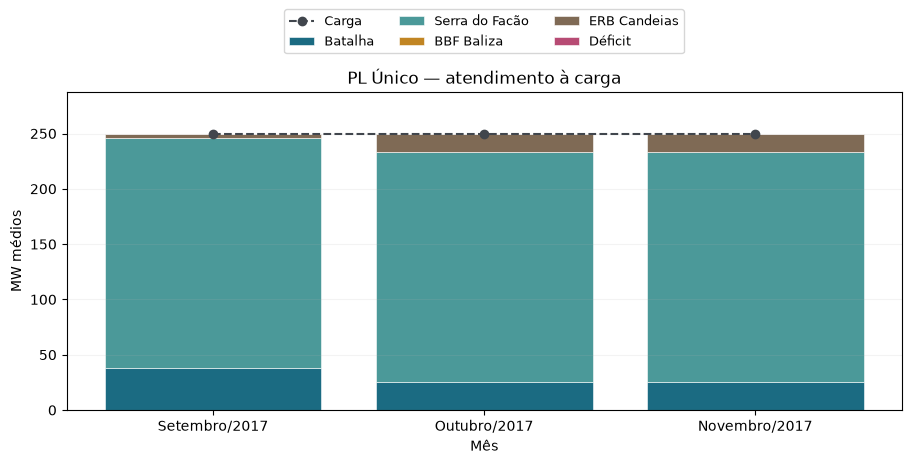

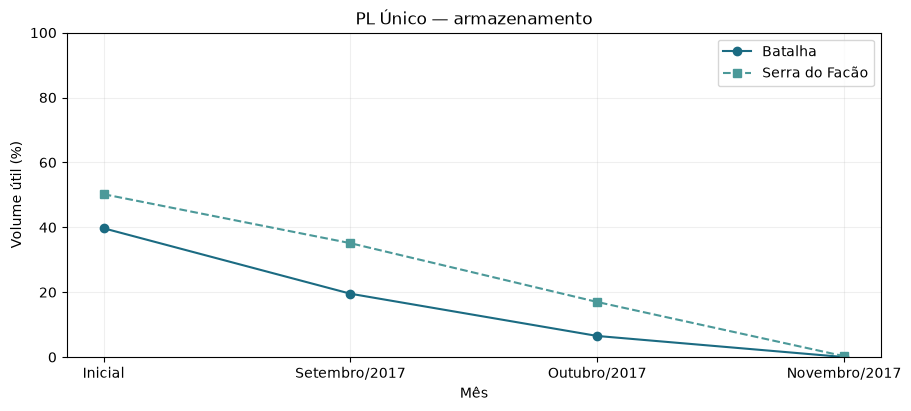

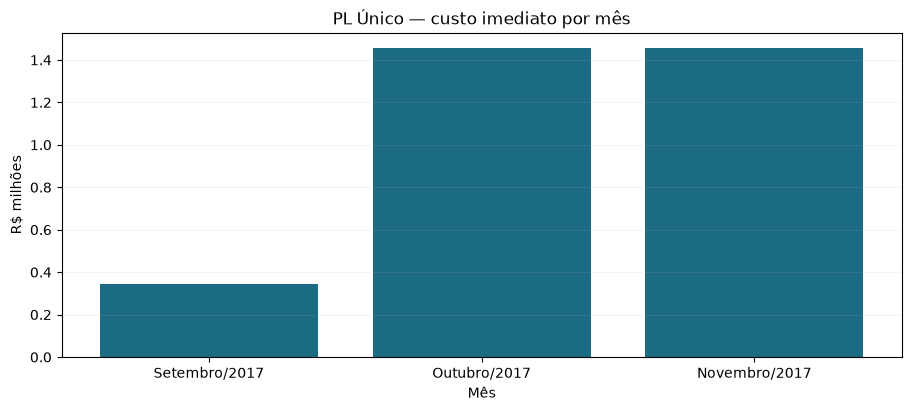

In [6]:
def graficos_metodo_det(sistema, resultado):
    meses = sistema['DGer']['Meses']
    traj, metodo = resultado['trajetoria'], resultado['metodo']
    nomes = [u['Nome'] for u in sistema['UHE']] + [u['Nome'] for u in sistema['UTE']] + ['Déficit']
    cores = ['#1B6B82', '#4B9999', '#C18523', '#7F6A55', '#B74B74']
    valores = np.array([[u['Prod']*r['vt'][i] for i, u in enumerate(sistema['UHE'])] +
                        r['gt'].tolist() + [max(0., r['def'])] for r in traj])
    fig, ax = plt.subplots(figsize=(9, 4.5), layout='constrained')
    acumulado = np.zeros(len(meses))
    for i, nome in enumerate(nomes):
        ax.bar(meses, valores[:, i], bottom=acumulado, color=cores[i], label=nome,
               edgecolor='white', linewidth=.4)
        acumulado += valores[:, i]
    ax.plot(meses, sistema['DGer']['Carga'], 'o--', color='#41464D', label='Carga')
    ax.set(title=f'{metodo} — atendimento à carga', xlabel='Mês', ylabel='MW médios',
           ylim=(0, max(1., max(sistema['DGer']['Carga'])*1.15)))
    ax.legend(ncol=3, loc='upper center', bbox_to_anchor=(.5, 1.28), fontsize=9)
    ax.grid(axis='y', alpha=.15)
    plt.show()

    fig, ax = plt.subplots(figsize=(9, 4), layout='constrained')
    for i, u in enumerate(sistema['UHE']):
        volumes = np.array([u['VI']] + [r['vf'][i] for r in traj])
        ax.plot(['Inicial', *meses], 100*(volumes-u['Vmin'])/(u['Vmax']-u['Vmin']),
                marker='o' if i == 0 else 's', linestyle='-' if i == 0 else '--',
                color=cores[i], label=u['Nome'])
    ax.set(title=f'{metodo} — armazenamento', xlabel='Mês', ylabel='Volume útil (%)', ylim=(0, 100))
    ax.legend()
    ax.grid(alpha=.2)
    plt.show()

    fig, ax = plt.subplots(figsize=(9, 4), layout='constrained')
    ax.bar(meses, [r['ci']/1e6 for r in traj], color='#1B6B82')
    ax.set(title=f'{metodo} — custo imediato por mês', xlabel='Mês', ylabel='R$ milhões', ylim=(0, None))
    ax.grid(axis='y', alpha=.15)
    plt.show()

    if 'historico' in resultado:
        hist = resultado['historico']
        fig, ax = plt.subplots(figsize=(9, 4), layout='constrained')
        ax.plot(hist['Iteração'], hist['ZINF (R$)']/1e6, 'o-', color='#1B6B82', label='ZINF — limite inferior')
        ax.plot(hist['Iteração'], hist['ZSUP (R$)']/1e6, 's--', color='#C18523', label='ZSUP — custo viável')
        ax.set(title=f'{metodo} — convergência', xlabel='Iteração', ylabel='R$ milhões', xticks=hist['Iteração'])
        ax.legend()
        ax.grid(alpha=.2)
        plt.show()


graficos_metodo_det(sistema_lido, resultado_lido)
